In [3]:
import tensorflow
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam


In [6]:
# Set image size and path
IMAGE_SIZE = 64
CHANNELS = 3
BATCH_SIZE = 64
DATA_DIR = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\images"  # Modify if needed

# Load and preprocess images
def load_images_from_folder(folder):
    images = []
    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)
        try:
            img = Image.open(path).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
            img_array = np.asarray(img) / 127.5 - 1  # Normalize to [-1, 1]
            images.append(img_array)
        except:
            continue
    return np.array(images)

images = load_images_from_folder(DATA_DIR)
print(f"Loaded {len(images)} images.")

dataset = tf.data.Dataset.from_tensor_slices(images).shuffle(1000).batch(BATCH_SIZE)


Loaded 10015 images.


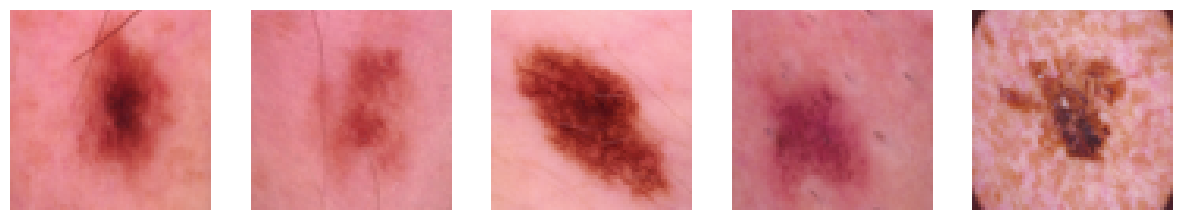

In [7]:
# Display a few sample images from the loaded dataset
num_samples = 5
plt.figure(figsize=(15, 3))
for i in range(num_samples):
    plt.subplot(1, num_samples, i + 1)
    img = (images[i] + 1) / 2  # Rescale to [0, 1] for display
    plt.imshow(img)
    plt.axis('off')
plt.show()

In [8]:
def build_generator():
    model = Sequential()
    model.add(layers.Dense(8*8*256, use_bias=False, input_shape=(100,)))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Reshape((8, 8, 256)))

    model.add(layers.Conv2DTranspose(128, kernel_size=4, strides=2, padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(64, kernel_size=4, strides=2, padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(CHANNELS, kernel_size=4, strides=2, padding='same', use_bias=False, activation='tanh'))

    return model


In [9]:
def build_discriminator():
    model = Sequential()
    model.add(layers.Conv2D(64, kernel_size=4, strides=2, padding='same', input_shape=(64, 64, 3)))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, kernel_size=4, strides=2, padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))

    return model


In [10]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator = build_generator()
discriminator = build_discriminator()

generator_optimizer = Adam(1e-4, beta_1=0.5)
discriminator_optimizer = Adam(1e-4, beta_1=0.5)


c:\Users\devgo\OneDrive\Desktop\project\.venv\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\devgo\OneDrive\Desktop\project\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
EPOCHS = 20000
noise_dim = 100
num_examples_to_generate = 16

seed = tf.random.normal([num_examples_to_generate, noise_dim])

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))


Epoch 0 - Gen Loss: 0.7788, Disc Loss: 1.3188 - Time: 52.19s


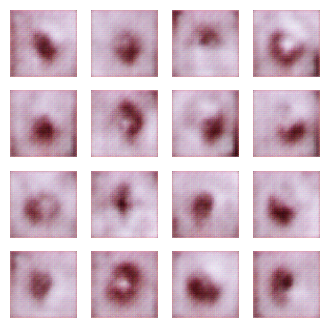

Epoch 1 - Gen Loss: 0.7881, Disc Loss: 1.2997 - Time: 52.66s
Epoch 2 - Gen Loss: 0.7615, Disc Loss: 1.3424 - Time: 54.21s
Epoch 3 - Gen Loss: 0.7517, Disc Loss: 1.3473 - Time: 54.05s
Epoch 4 - Gen Loss: 0.7538, Disc Loss: 1.3384 - Time: 53.76s
Epoch 5 - Gen Loss: 0.7425, Disc Loss: 1.3484 - Time: 54.46s
Epoch 6 - Gen Loss: 0.7410, Disc Loss: 1.3545 - Time: 59.08s
Epoch 7 - Gen Loss: 0.7382, Disc Loss: 1.3546 - Time: 54.06s
Epoch 8 - Gen Loss: 0.7379, Disc Loss: 1.3558 - Time: 53.82s
Epoch 9 - Gen Loss: 0.7371, Disc Loss: 1.3572 - Time: 54.73s
Epoch 10 - Gen Loss: 0.7395, Disc Loss: 1.3541 - Time: 58.62s
Epoch 11 - Gen Loss: 0.7464, Disc Loss: 1.3484 - Time: 54.34s
Epoch 12 - Gen Loss: 0.7510, Disc Loss: 1.3447 - Time: 53.98s
Epoch 13 - Gen Loss: 0.7520, Disc Loss: 1.3385 - Time: 53.85s
Epoch 14 - Gen Loss: 0.7463, Disc Loss: 1.3462 - Time: 54.09s
Epoch 15 - Gen Loss: 0.7505, Disc Loss: 1.3409 - Time: 54.03s
Epoch 16 - Gen Loss: 0.7581, Disc Loss: 1.3351 - Time: 54.11s
Epoch 17 - Gen Lo

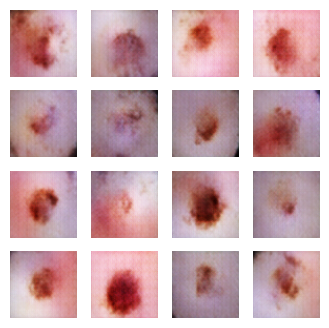

Epoch 101 - Gen Loss: 0.7558, Disc Loss: 1.3455 - Time: 54.76s
Epoch 102 - Gen Loss: 0.7566, Disc Loss: 1.3451 - Time: 54.52s
Epoch 103 - Gen Loss: 0.7590, Disc Loss: 1.3376 - Time: 54.32s
Epoch 104 - Gen Loss: 0.7615, Disc Loss: 1.3390 - Time: 54.02s
Epoch 105 - Gen Loss: 0.7496, Disc Loss: 1.3474 - Time: 54.52s
Epoch 106 - Gen Loss: 0.7527, Disc Loss: 1.3449 - Time: 54.39s
Epoch 107 - Gen Loss: 0.7506, Disc Loss: 1.3463 - Time: 54.24s
Epoch 108 - Gen Loss: 0.7503, Disc Loss: 1.3474 - Time: 54.30s
Epoch 109 - Gen Loss: 0.7664, Disc Loss: 1.3325 - Time: 54.12s
Epoch 110 - Gen Loss: 0.7594, Disc Loss: 1.3411 - Time: 54.12s
Epoch 111 - Gen Loss: 0.7565, Disc Loss: 1.3414 - Time: 54.05s
Epoch 112 - Gen Loss: 0.7613, Disc Loss: 1.3390 - Time: 54.11s
Epoch 113 - Gen Loss: 0.7574, Disc Loss: 1.3412 - Time: 53.87s
Epoch 114 - Gen Loss: 0.7668, Disc Loss: 1.3307 - Time: 53.96s
Epoch 115 - Gen Loss: 0.7526, Disc Loss: 1.3421 - Time: 54.09s
Epoch 116 - Gen Loss: 0.7572, Disc Loss: 1.3421 - Time:

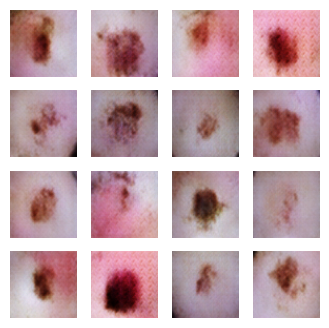

Epoch 201 - Gen Loss: 0.7656, Disc Loss: 1.3380 - Time: 54.10s
Epoch 202 - Gen Loss: 0.7628, Disc Loss: 1.3379 - Time: 54.13s
Epoch 203 - Gen Loss: 0.7704, Disc Loss: 1.3308 - Time: 54.04s
Epoch 204 - Gen Loss: 0.7602, Disc Loss: 1.3445 - Time: 54.36s
Epoch 205 - Gen Loss: 0.7591, Disc Loss: 1.3418 - Time: 54.10s
Epoch 206 - Gen Loss: 0.7630, Disc Loss: 1.3367 - Time: 54.04s
Epoch 207 - Gen Loss: 0.7722, Disc Loss: 1.3297 - Time: 54.08s
Epoch 208 - Gen Loss: 0.7662, Disc Loss: 1.3370 - Time: 54.29s
Epoch 209 - Gen Loss: 0.7690, Disc Loss: 1.3316 - Time: 53.94s
Epoch 210 - Gen Loss: 0.7676, Disc Loss: 1.3326 - Time: 53.98s
Epoch 211 - Gen Loss: 0.7585, Disc Loss: 1.3430 - Time: 54.11s
Epoch 212 - Gen Loss: 0.7703, Disc Loss: 1.3320 - Time: 53.80s
Epoch 213 - Gen Loss: 0.7709, Disc Loss: 1.3335 - Time: 54.20s
Epoch 214 - Gen Loss: 0.7706, Disc Loss: 1.3320 - Time: 53.92s
Epoch 215 - Gen Loss: 0.7602, Disc Loss: 1.3406 - Time: 53.70s
Epoch 216 - Gen Loss: 0.7613, Disc Loss: 1.3396 - Time:

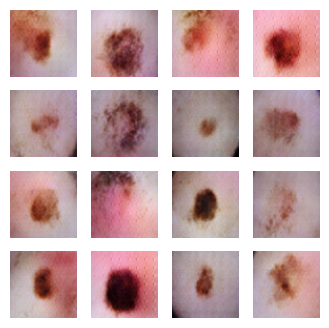

Epoch 301 - Gen Loss: 0.7707, Disc Loss: 1.3432 - Time: 81.72s
Epoch 302 - Gen Loss: 0.7730, Disc Loss: 1.3355 - Time: 66.21s
Epoch 303 - Gen Loss: 0.7668, Disc Loss: 1.3424 - Time: 66.22s
Epoch 304 - Gen Loss: 0.7643, Disc Loss: 1.3411 - Time: 67.94s
Epoch 305 - Gen Loss: 0.7664, Disc Loss: 1.3399 - Time: 67.28s
Epoch 306 - Gen Loss: 0.7705, Disc Loss: 1.3357 - Time: 65.82s
Epoch 307 - Gen Loss: 0.7708, Disc Loss: 1.3387 - Time: 66.14s
Epoch 308 - Gen Loss: 0.7626, Disc Loss: 1.3398 - Time: 66.33s
Epoch 309 - Gen Loss: 0.7671, Disc Loss: 1.3396 - Time: 66.35s
Epoch 310 - Gen Loss: 0.7719, Disc Loss: 1.3370 - Time: 66.83s
Epoch 311 - Gen Loss: 0.7706, Disc Loss: 1.3341 - Time: 66.79s
Epoch 312 - Gen Loss: 0.7714, Disc Loss: 1.3345 - Time: 67.23s
Epoch 313 - Gen Loss: 0.7669, Disc Loss: 1.3373 - Time: 67.19s
Epoch 314 - Gen Loss: 0.7664, Disc Loss: 1.3395 - Time: 66.79s
Epoch 315 - Gen Loss: 0.7699, Disc Loss: 1.3345 - Time: 66.93s
Epoch 316 - Gen Loss: 0.7696, Disc Loss: 1.3390 - Time:

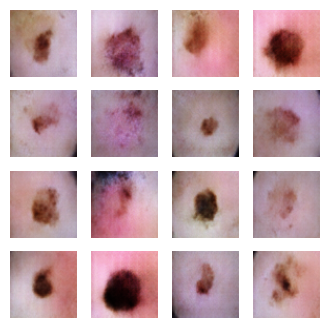

Epoch 401 - Gen Loss: 0.7795, Disc Loss: 1.3319 - Time: 55.67s
Epoch 402 - Gen Loss: 0.7815, Disc Loss: 1.3328 - Time: 54.14s
Epoch 403 - Gen Loss: 0.7720, Disc Loss: 1.3341 - Time: 54.17s
Epoch 404 - Gen Loss: 0.7751, Disc Loss: 1.3408 - Time: 54.35s
Epoch 405 - Gen Loss: 0.7725, Disc Loss: 1.3375 - Time: 54.25s
Epoch 406 - Gen Loss: 0.7759, Disc Loss: 1.3367 - Time: 53.81s
Epoch 407 - Gen Loss: 0.7733, Disc Loss: 1.3310 - Time: 54.25s
Epoch 408 - Gen Loss: 0.7735, Disc Loss: 1.3365 - Time: 54.18s
Epoch 409 - Gen Loss: 0.7623, Disc Loss: 1.3438 - Time: 54.35s
Epoch 410 - Gen Loss: 0.7688, Disc Loss: 1.3375 - Time: 54.14s
Epoch 411 - Gen Loss: 0.7724, Disc Loss: 1.3400 - Time: 54.03s
Epoch 412 - Gen Loss: 0.7676, Disc Loss: 1.3404 - Time: 53.91s
Epoch 413 - Gen Loss: 0.7677, Disc Loss: 1.3400 - Time: 54.31s
Epoch 414 - Gen Loss: 0.7687, Disc Loss: 1.3377 - Time: 54.13s
Epoch 415 - Gen Loss: 0.7715, Disc Loss: 1.3407 - Time: 54.03s
Epoch 416 - Gen Loss: 0.7746, Disc Loss: 1.3352 - Time:

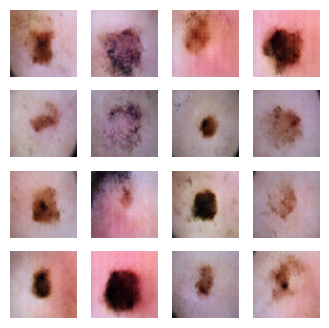

Epoch 501 - Gen Loss: 0.7649, Disc Loss: 1.3441 - Time: 56.05s
Epoch 502 - Gen Loss: 0.7620, Disc Loss: 1.3447 - Time: 54.68s
Epoch 503 - Gen Loss: 0.7652, Disc Loss: 1.3436 - Time: 54.42s
Epoch 504 - Gen Loss: 0.7665, Disc Loss: 1.3386 - Time: 54.08s
Epoch 505 - Gen Loss: 0.7582, Disc Loss: 1.3434 - Time: 54.10s
Epoch 506 - Gen Loss: 0.7601, Disc Loss: 1.3471 - Time: 54.28s
Epoch 507 - Gen Loss: 0.7559, Disc Loss: 1.3538 - Time: 54.29s
Epoch 508 - Gen Loss: 0.7626, Disc Loss: 1.3407 - Time: 54.15s
Epoch 509 - Gen Loss: 0.7659, Disc Loss: 1.3405 - Time: 54.28s
Epoch 510 - Gen Loss: 0.7646, Disc Loss: 1.3455 - Time: 54.12s
Epoch 511 - Gen Loss: 0.7668, Disc Loss: 1.3395 - Time: 54.25s
Epoch 512 - Gen Loss: 0.7658, Disc Loss: 1.3406 - Time: 53.92s
Epoch 513 - Gen Loss: 0.7671, Disc Loss: 1.3391 - Time: 53.95s
Epoch 514 - Gen Loss: 0.7635, Disc Loss: 1.3434 - Time: 55.10s
Epoch 515 - Gen Loss: 0.7666, Disc Loss: 1.3398 - Time: 54.29s
Epoch 516 - Gen Loss: 0.7612, Disc Loss: 1.3460 - Time:

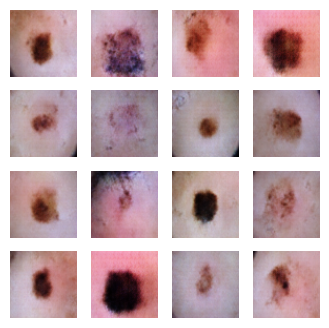

Epoch 601 - Gen Loss: 0.7763, Disc Loss: 1.3321 - Time: 53.72s
Epoch 602 - Gen Loss: 0.7696, Disc Loss: 1.3385 - Time: 53.96s
Epoch 603 - Gen Loss: 0.7695, Disc Loss: 1.3354 - Time: 53.86s
Epoch 604 - Gen Loss: 0.7760, Disc Loss: 1.3347 - Time: 54.68s
Epoch 605 - Gen Loss: 0.7692, Disc Loss: 1.3393 - Time: 53.90s
Epoch 606 - Gen Loss: 0.7676, Disc Loss: 1.3390 - Time: 53.99s
Epoch 607 - Gen Loss: 0.7686, Disc Loss: 1.3347 - Time: 53.90s
Epoch 608 - Gen Loss: 0.7651, Disc Loss: 1.3410 - Time: 54.16s
Epoch 609 - Gen Loss: 0.7679, Disc Loss: 1.3409 - Time: 53.84s
Epoch 610 - Gen Loss: 0.7750, Disc Loss: 1.3329 - Time: 53.81s
Epoch 611 - Gen Loss: 0.7710, Disc Loss: 1.3373 - Time: 53.88s
Epoch 612 - Gen Loss: 0.7628, Disc Loss: 1.3484 - Time: 53.83s
Epoch 613 - Gen Loss: 0.7648, Disc Loss: 1.3380 - Time: 54.11s
Epoch 614 - Gen Loss: 0.7633, Disc Loss: 1.3441 - Time: 53.74s
Epoch 615 - Gen Loss: 0.7691, Disc Loss: 1.3358 - Time: 53.85s
Epoch 616 - Gen Loss: 0.7698, Disc Loss: 1.3396 - Time:

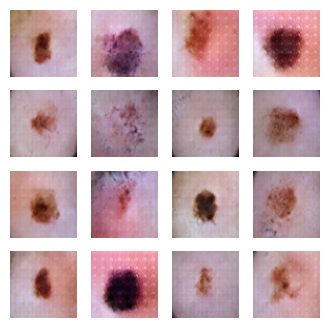

Epoch 701 - Gen Loss: 0.7857, Disc Loss: 1.3269 - Time: 54.13s
Epoch 702 - Gen Loss: 0.7867, Disc Loss: 1.3253 - Time: 54.27s
Epoch 703 - Gen Loss: 0.7868, Disc Loss: 1.3216 - Time: 53.89s
Epoch 704 - Gen Loss: 0.7839, Disc Loss: 1.3263 - Time: 54.07s
Epoch 705 - Gen Loss: 0.7828, Disc Loss: 1.3270 - Time: 53.88s
Epoch 706 - Gen Loss: 0.7875, Disc Loss: 1.3199 - Time: 54.34s
Epoch 707 - Gen Loss: 0.7873, Disc Loss: 1.3255 - Time: 54.03s
Epoch 708 - Gen Loss: 0.7874, Disc Loss: 1.3236 - Time: 53.97s
Epoch 709 - Gen Loss: 0.7869, Disc Loss: 1.3205 - Time: 53.96s
Epoch 710 - Gen Loss: 0.7825, Disc Loss: 1.3272 - Time: 54.13s
Epoch 711 - Gen Loss: 0.7820, Disc Loss: 1.3276 - Time: 53.83s
Epoch 712 - Gen Loss: 0.7823, Disc Loss: 1.3333 - Time: 53.99s
Epoch 713 - Gen Loss: 0.7863, Disc Loss: 1.3192 - Time: 54.06s
Epoch 714 - Gen Loss: 0.7843, Disc Loss: 1.3275 - Time: 54.21s
Epoch 715 - Gen Loss: 0.7817, Disc Loss: 1.3308 - Time: 54.31s
Epoch 716 - Gen Loss: 0.7876, Disc Loss: 1.3297 - Time:

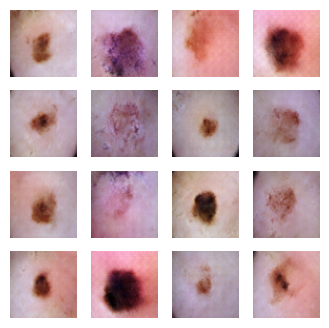

Epoch 801 - Gen Loss: 0.7769, Disc Loss: 1.3415 - Time: 53.97s
Epoch 802 - Gen Loss: 0.7832, Disc Loss: 1.3255 - Time: 53.92s
Epoch 803 - Gen Loss: 0.7780, Disc Loss: 1.3314 - Time: 54.24s
Epoch 804 - Gen Loss: 0.7762, Disc Loss: 1.3324 - Time: 53.73s
Epoch 805 - Gen Loss: 0.7792, Disc Loss: 1.3301 - Time: 53.67s
Epoch 806 - Gen Loss: 0.7750, Disc Loss: 1.3291 - Time: 54.08s
Epoch 807 - Gen Loss: 0.7815, Disc Loss: 1.3301 - Time: 54.16s
Epoch 808 - Gen Loss: 0.7880, Disc Loss: 1.3263 - Time: 54.15s
Epoch 809 - Gen Loss: 0.7851, Disc Loss: 1.3356 - Time: 53.90s
Epoch 810 - Gen Loss: 0.7812, Disc Loss: 1.3292 - Time: 53.83s
Epoch 811 - Gen Loss: 0.7808, Disc Loss: 1.3357 - Time: 53.83s
Epoch 812 - Gen Loss: 0.7770, Disc Loss: 1.3300 - Time: 54.26s
Epoch 813 - Gen Loss: 0.7888, Disc Loss: 1.3232 - Time: 53.87s
Epoch 814 - Gen Loss: 0.7827, Disc Loss: 1.3295 - Time: 54.10s
Epoch 815 - Gen Loss: 0.7784, Disc Loss: 1.3362 - Time: 53.79s
Epoch 816 - Gen Loss: 0.7819, Disc Loss: 1.3302 - Time:

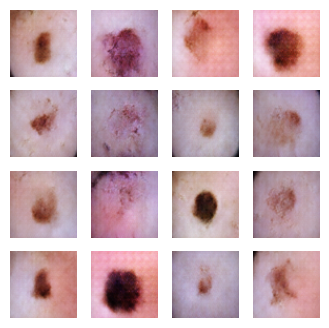

Epoch 901 - Gen Loss: 0.7773, Disc Loss: 1.3315 - Time: 54.25s
Epoch 902 - Gen Loss: 0.7792, Disc Loss: 1.3309 - Time: 53.91s
Epoch 903 - Gen Loss: 0.7851, Disc Loss: 1.3277 - Time: 54.05s
Epoch 904 - Gen Loss: 0.7761, Disc Loss: 1.3323 - Time: 54.22s
Epoch 905 - Gen Loss: 0.7870, Disc Loss: 1.3281 - Time: 54.29s
Epoch 906 - Gen Loss: 0.7786, Disc Loss: 1.3314 - Time: 54.14s
Epoch 907 - Gen Loss: 0.7757, Disc Loss: 1.3376 - Time: 53.97s
Epoch 908 - Gen Loss: 0.7818, Disc Loss: 1.3260 - Time: 54.10s
Epoch 909 - Gen Loss: 0.7795, Disc Loss: 1.3331 - Time: 54.10s
Epoch 910 - Gen Loss: 0.7898, Disc Loss: 1.3326 - Time: 54.26s
Epoch 911 - Gen Loss: 0.7777, Disc Loss: 1.3314 - Time: 53.97s
Epoch 912 - Gen Loss: 0.7746, Disc Loss: 1.3345 - Time: 53.88s
Epoch 913 - Gen Loss: 0.7735, Disc Loss: 1.3340 - Time: 54.00s
Epoch 914 - Gen Loss: 0.7739, Disc Loss: 1.3371 - Time: 54.31s
Epoch 915 - Gen Loss: 0.7809, Disc Loss: 1.3307 - Time: 54.17s
Epoch 916 - Gen Loss: 0.7868, Disc Loss: 1.3227 - Time:

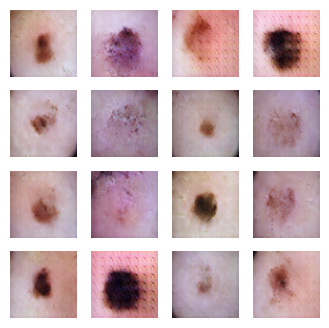

Epoch 1001 - Gen Loss: 0.8018, Disc Loss: 1.3104 - Time: 54.59s
Epoch 1002 - Gen Loss: 0.7837, Disc Loss: 1.3343 - Time: 54.63s
Epoch 1003 - Gen Loss: 0.7881, Disc Loss: 1.3323 - Time: 54.96s
Epoch 1004 - Gen Loss: 0.7888, Disc Loss: 1.3241 - Time: 54.53s
Epoch 1005 - Gen Loss: 0.7896, Disc Loss: 1.3252 - Time: 54.72s
Epoch 1006 - Gen Loss: 0.7816, Disc Loss: 1.3272 - Time: 55.50s
Epoch 1007 - Gen Loss: 0.7793, Disc Loss: 1.3313 - Time: 54.76s
Epoch 1008 - Gen Loss: 0.7779, Disc Loss: 1.3291 - Time: 55.73s
Epoch 1009 - Gen Loss: 0.7762, Disc Loss: 1.3356 - Time: 54.68s
Epoch 1010 - Gen Loss: 0.7796, Disc Loss: 1.3284 - Time: 54.47s
Epoch 1011 - Gen Loss: 0.7733, Disc Loss: 1.3343 - Time: 54.48s
Epoch 1012 - Gen Loss: 0.7728, Disc Loss: 1.3372 - Time: 54.62s
Epoch 1013 - Gen Loss: 0.7808, Disc Loss: 1.3333 - Time: 54.60s
Epoch 1014 - Gen Loss: 0.7880, Disc Loss: 1.3302 - Time: 54.42s
Epoch 1015 - Gen Loss: 0.7933, Disc Loss: 1.3189 - Time: 54.24s
Epoch 1016 - Gen Loss: 0.7926, Disc Loss

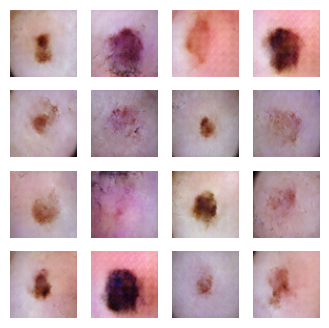

Epoch 1101 - Gen Loss: 0.7792, Disc Loss: 1.3362 - Time: 54.11s
Epoch 1102 - Gen Loss: 0.7846, Disc Loss: 1.3211 - Time: 53.87s


KeyboardInterrupt: 

In [13]:
import time
import os

def generate_and_save_images(model, epoch, test_input, display=False):
    predictions = model(test_input, training=False)
    fig = plt.figure(figsize=(4, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i+1)
        img = (predictions[i] + 1) / 2  # Rescale to [0, 1]
        plt.imshow(img)
        plt.axis('off')
    plt.savefig(f'gan_images/image_at_epoch_{epoch:04d}.png')
    if display:
        plt.show()
    plt.close()

os.makedirs('gan_images', exist_ok=True)

def train(dataset, epochs):
    for epoch in range(epochs):
        start = time.time()
        g_losses = []
        d_losses = []
        for image_batch in dataset:
            noise = tf.random.normal([BATCH_SIZE, noise_dim])
            with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
                generated_images = generator(noise, training=True)

                real_output = discriminator(image_batch, training=True)
                fake_output = discriminator(generated_images, training=True)

                gen_loss = generator_loss(fake_output)
                disc_loss = discriminator_loss(real_output, fake_output)

            gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
            gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

            generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
            discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

            g_losses.append(gen_loss.numpy())
            d_losses.append(disc_loss.numpy())

        avg_g_loss = np.mean(g_losses)
        avg_d_loss = np.mean(d_losses)
        print(f"Epoch {epoch} - Gen Loss: {avg_g_loss:.4f}, Disc Loss: {avg_d_loss:.4f} - Time: {time.time() - start:.2f}s")

        if epoch % 100 == 0:
            generate_and_save_images(generator, epoch, seed, display=True)

train(dataset, EPOCHS)


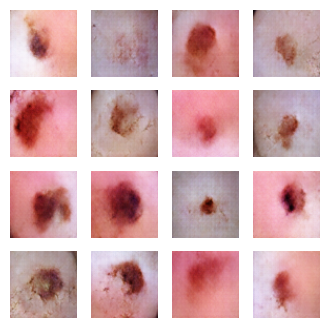

In [14]:
# Generate new images using the trained generator
new_noise = tf.random.normal([num_examples_to_generate, noise_dim])
generated_images = generator(new_noise, training=False)

plt.figure(figsize=(4, 4))
for i in range(num_examples_to_generate):
    plt.subplot(4, 4, i + 1)
    img = (generated_images[i] + 1) / 2  # Rescale to [0, 1]
    plt.imshow(img)
    plt.axis('off')
plt.show()

In [2]:
# Generate 50 new images using the trained generator and save them as separate files
num_images = 50
noise = tf.random.normal([num_images, noise_dim])
generated_imgs = generator(noise, training=False)

output_dir = 'gan_generated_samples'
os.makedirs(output_dir, exist_ok=True)

for idx in range(num_images):
    img = (generated_imgs[idx].numpy() + 1) / 2  # Rescale to [0, 1]
    img = (img * 255).astype(np.uint8)
    im = Image.fromarray(img)
    im.save(os.path.join(output_dir, f'gen_image_{idx+1:03d}.png'))

NameError: name 'tf' is not defined

In [1]:
plt.figure(figsize=(10, 10))
for i in range(num_images):
    plt.subplot(5, 10, i + 1)
    img = (generated_imgs[i].numpy() + 1) / 2  # Rescale to [0, 1]
    plt.imshow(img)
    plt.axis('off')
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined